# Unsupervised Learning

## Import

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from collections import Counter

## Preprocess

Le but de cette division nous permet de prendre le CSV initial et d'en normaliser les données afin de pouvoir les faire analyser par l'IA plus efficacement.

On va créer un nouveau CSV avec 3 colonnes : chiffre couleur et phrase(symptome)

Le but va être de séparer les données du CSV inital qui ne possède pas de labals. Pour ceci, on va séparer les données aux virgules.
On enlève les guillemets qui ne sont pas toujours présente pour n'avoir que le symptôme propre sans avoir d'élément parasites.

In [2]:
df = pd.DataFrame(columns=["chiffre", "couleur", "phrase"])

with open("Student_Dataset.csv", "r", encoding="utf-8") as fichier:

    for ligne in fichier:
        ligne = ligne.strip()

        chiffre, phrase = ligne.split(",", 1)

        if "0x000000" in phrase:
            couleur, symptome = phrase.split(",", 1)
            symptome = symptome.replace('"', "")
            df.loc[len(df)] = [chiffre, couleur, symptome]

        else :
            phrase = phrase.replace('"', "")
            df.loc[len(df)] = [chiffre, "", phrase]

df.to_csv("Nouveau_Dataset.csv", index=False)

## Vérification

Pour vérifier que tout à été bien ajouté correctement, on vérifie la longueur des trois colonnes.

Et qu'il n'y est pas de vide dans les colonnes chiffre et phrase

In [3]:
print("Longueur de la colonne chiffre :", len(df["chiffre"]))
print("Longueur de la colonne couleur :", len(df["couleur"]))
print("Longueur de la colonne phrase :", len(df["phrase"]))

for k in df["chiffre"]:
    if k == "" or k == None:
        print("Erreur de valeur")

for k in df["phrase"]:
    if k == "" or k == None:
        print("Erreur de valeur")

Longueur de la colonne chiffre : 1011
Longueur de la colonne couleur : 1011
Longueur de la colonne phrase : 1011


## TF-IDF Vectorizer

Pour pouvoir entrainer notre IA, on va trasformer tous les mots en vecteur, qui seront compréhensible par notre IA.

On obtient également le nombre de mots différents parmi les 1011 lignes composant le dataset.

Pour éviter d'être embetté par des mots non pertinents au problème, on vectorise en enlevant les stop-words(the, a ...) afin de ne garder que des mots relatifs aux symptomes.

In [4]:
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(df["phrase"])
noms = vectorizer.get_feature_names_out()
print(X.shape)

(1011, 2135)


## TruncatedSVD

In [5]:
resultats = []

for n_comp in range(10, 101, 10):
    svd = TruncatedSVD(n_components=n_comp, random_state=42)
    X_reduced = svd.fit_transform(X)

    for k in range(2, 40):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto").fit(X_reduced)
        score = silhouette_score(X_reduced, kmeans.labels_)
        resultats.append((n_comp, k, score))

df_resultats = pd.DataFrame(resultats, columns=["n_components", "k", "silhouette"])

print(df_resultats)

meilleur = df_resultats.loc[df_resultats["silhouette"].idxmax()]
print("Meilleure combinaison (sans contrainte) :\n", meilleur)

svd_final = TruncatedSVD(n_components=10, random_state=42)
X_reduced_final = svd_final.fit_transform(X)
print("Variance expliquée avec 10 composantes :", svd_final.explained_variance_ratio_.sum())

     n_components   k  silhouette
0              10   2    0.097189
1              10   3    0.143042
2              10   4    0.170457
3              10   5    0.204947
4              10   6    0.183061
..            ...  ..         ...
375           100  35    0.054474
376           100  36    0.056862
377           100  37    0.056578
378           100  38    0.058869
379           100  39    0.057955

[380 rows x 3 columns]
Meilleure combinaison (sans contrainte) :
 n_components    10.00000
k               10.00000
silhouette       0.30411
Name: 8, dtype: float64
Variance expliquée avec 10 composantes : 0.08178656052937838


## Loss Function (Unsupervised)

Dans notre partie non supervisée, la fonction de perte (ou loss function) s'appelle l'inertie. Elle calcule la somme des distances au carré entre chaque point de donnée et le centre du cluster auquel il est assigné. L'algorithme KMeans cherche constamment à minimiser cette valeur à chaque itération pour rendre les groupes les plus compacts et homogènes possible. Concrètement, nous l'utilisons avec la Elbow Method pour identifier le nombre optimal de clusters, c'est-à-dire le point où la baisse de l'inertie commence à ralentir. Ainsi, une inertie plus faible garantit que les symptômes regroupés dans un même cluster partagent des similarités sémantiques fortes et médicalement cohérentes.

## Elbow Method (Inertias)

Ensuite, nous faisons la "Elbow Method" (Méthode du coude) afin de déterminer une zone de valeurs idéales pour trouver notre nombre de cluster le plus efficace.

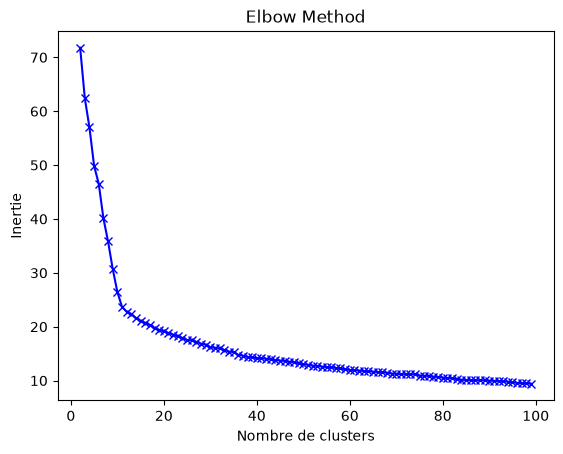

In [6]:

inertias = []
K = range(2, 100)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42).fit(X_reduced_final)
    inertias.append(kmeanModel.inertia_)

plt.plot(K, inertias, 'bx-')
plt.xlabel('Nombre de clusters')
plt.ylabel('Inertie')
plt.title("Elbow Method")
plt.show()

Pour obtenir plus de précision, nous utilisons une silhouette score afin d'avoir une meilleure précision sur le nombre de clusters idéal pour regrouper nos différents mots.

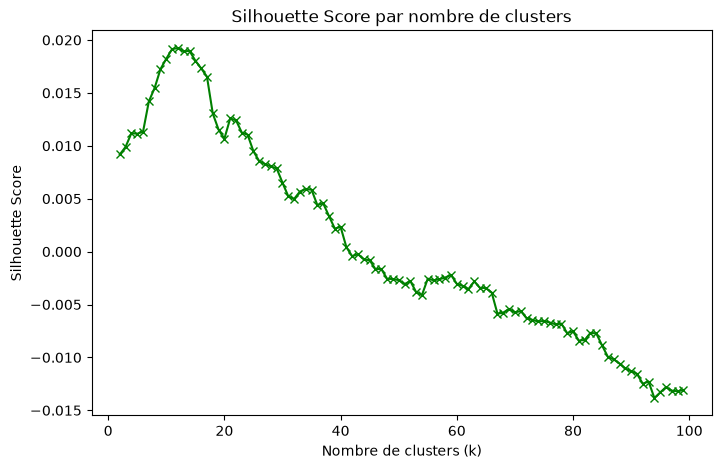

In [7]:
silhouette_scores = []
K2 = range(2, 100)

for k in K2:
    kmeanModel = KMeans(n_clusters=k, random_state=42).fit(X_reduced_final)
    score = silhouette_score(X, kmeanModel.labels_)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(K2, silhouette_scores, 'gx-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title("Silhouette Score par nombre de clusters")
plt.show()

## Première conclusion

Grâce à notre vérifacation entre le nombre de components de TruncatedSVD et le nombre de clusters, on en vient à la conclusion que le meilleur assemblages est 10 components avec 10 clusters pour un score de 0.30411. 

On peut d'ailleurs vérifier ceci à l'aide de deux graphiques générés par une Elbow method et un silhouette score. Ils donnent chacun correlation sur 
ce résultat de 10 clusters.

Au delà de cela, on reconnait qu'avoir une dixaine de clusters ressemble à la réalité. Notre but est de grouper les symptomes, mais surtout de grouper les symptomes comme un médecin pourrait le faire. 

Or un médecin ne va pas faire 100/200 groupes de personnes qui serait absolument impossible à gérer facilement. 

La présence d'un pic entre 10 à 13 clusters de notre coefficient de silhouette va également dans notre sens, car le groupage des différents individus en une dixaine de groupe est cohérent avec ce qui peut se faire dans la réalité.

Nous décidons donc de partir sur ce nombre de clusters afin de regrouper nos symptômes de la manière la plus efficace et humaine possible.

## Clustering

On met donc notre nombre de cluster à 19, et on regroupe nos mots dans ceux-ci. 

On vérifie ensuite que nous obtenons un regroupement assez précis et adhéquat entre les éléments.

In [8]:
k_final = 10

kmeans = KMeans(n_clusters=k_final, random_state=42, n_init="auto").fit(X_reduced_final)

centres_originaux = svd_final.inverse_transform(kmeans.cluster_centers_)

for k in range(k_final):
    indices = centres_originaux[k].argsort()[-10:][::-1]
    print(f"**** Cluster n°{k} ****")
    for l in indices:
        print(noms[l])
    print()

**** Cluster n°0 ****
feels
ache
shoulder
arm
deep
makes
gives
lifting
reaching
weak

**** Cluster n°1 ****
ache
sore
long
deep
makes
foot
ankle
leg
knee
pushing

**** Cluster n°2 ****
chest
cough
breath
feel
feels
tight
night
short
feeling
like

**** Cluster n°3 ****
ear
pain
fever
cold
slight
sharp
left
right
feel
hearing

**** Cluster n°4 ****
feel
skin
pale
headaches
notice
looks
dizzy
weak
think
stand

**** Cluster n°5 ****
itchy
rash
new
raised
spots
hives
like
painful
welts
bumps

**** Cluster n°6 ****
felt
throat
nose
mild
day
cough
cold
headache
runny
sore

**** Cluster n°7 ****
ve
doctor
blood
night
weight
thirsty
feel
losing
feeling
sugar

**** Cluster n°8 ****
pain
head
feel
starts
throbbing
vision
like
gets
pressure
worse

**** Cluster n°9 ****
hot
blister
skin
red
small
feels
touched
tender
area
hand



## Kmeans Modele

## Pourquoi avoir choisi KMeans ?

Nous avons choisi **KMeans** pour réaliser la partie non supervisée de notre étude, principalement parce qu’il est bien adapté à la nature de notre dataset.

1. **Un algorithme adapté à nos données :** Après avoir transformé les textes en données numériques grâce au TF-IDF, puis réduit leur dimension avec TruncatedSVD, nous obtenons un espace vectoriel. KMeans est particulièrement adapté à ce type de données puisqu’il permet de regrouper facilement les témoignages en fonction de leur similarité.

2. **Des résultats faciles à interpréter :** Avec KMeans, chaque témoignage est associé à un seul cluster. Dans notre contexte médical, cela nous permet d’identifier des groupes de patients partageant des symptômes ou des thématiques similaires. Cette approche rend donc les résultats plus simples à analyser et à interpréter.

3. **Un modèle simple et rapide :** KMeans est également intéressant car il est relativement simple à mettre en place et peu coûteux en temps de calcul. Il nous permet ainsi d’obtenir rapidement une première idée de la structure de notre dataset. Nous pouvons ensuite utiliser ces résultats comme point de comparaison avec des méthodes plus complexes, comme **DBSCAN** ou **GMM**, que nous étudierons par la suite.

## Comment fonctionne KMeans ?

Le fonctionnement de **KMeans** est assez simple. L’algorithme cherche progressivement à regrouper les données en **k groupes**, en rapprochant les points qui se ressemblent le plus. Pour cela, il répète plusieurs étapes jusqu’à ce que les groupes se stabilisent.

1. **Initialisation :** L’algorithme commence par choisir **k points** dans l’espace. Ces points correspondent aux **centroïdes**, c’est-à-dire aux centres des groupes que KMeans va essayer de former.

2. **Assignation des points :** Chaque donnée est ensuite associée au centroïde dont elle est la plus proche. Dans notre cas, il s’agit des vecteurs représentant les témoignages et leurs symptômes. La proximité est déterminée à partir de la distance entre les points.

3. **Mise à jour des centroïdes :** Une fois que tous les points ont été associés à un groupe, KMeans recalcule le centre de chaque cluster. Pour cela, il prend la moyenne de tous les points appartenant au groupe.

Ces trois étapes sont répétées plusieurs fois, jusqu’à ce que les centroïdes ne changent presque plus de position. On considère alors que l’algorithme a convergé.
Au final, les témoignages qui présentent des caractéristiques similaires dans notre espace vectoriel **TF-IDF + SVD** sont regroupés dans les mêmes clusters. Cela nous permet ainsi de faire ressortir des groupes de témoignages partageant des thématiques ou des symptômes proches.

/tmp/ipykernel_1153/3881369273.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


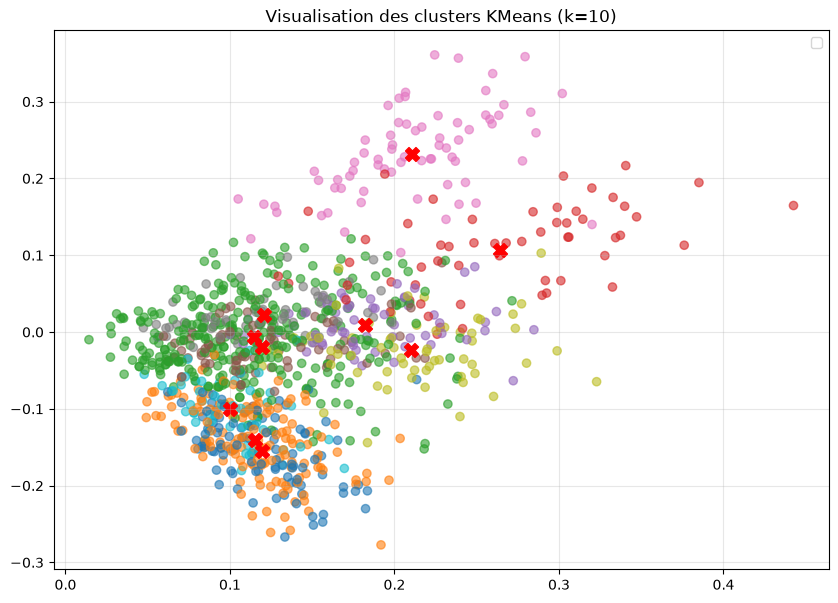

In [41]:
# Initialisation du modèle KMeans avec 10 clusters
kmeans_final = KMeans(n_clusters=10, random_state=42, n_init="auto")

# Entraînement du modèle et attribution des clusters aux données réduites
clusters = kmeans_final.fit_predict(X_reduced_final)

# 2 premier composants de la réduction svd
x_axis = X_reduced_final[:, 0]
y_axis = X_reduced_final[:, 1]

plt.figure(figsize=(10, 7))
scatter = plt.scatter(x_axis, y_axis, c=clusters, cmap='tab10', alpha=0.6)

# Récupération des coordonnées des centroïdes
centres_2d = kmeans_final.cluster_centers_[:, :2]

plt.title("Visualisation des clusters KMeans (k=10)")
plt.legend()

# Affichage des centroïdes sur le graphique
plt.scatter(centres_2d[:, 0], centres_2d[:, 1], c='red', marker='X', s=100, label='Centroides')
plt.grid(True, alpha=0.3)
plt.show()

## Clustering Hiérarchique Agglomératif

### Comment ça marche ?

Contrairement à KMeans, qui commence par définir des centres de groupes puis y associe les différents points, le **clustering agglomératif** fonctionne dans l’autre sens. Il part des données individuelles et construit progressivement les groupes, d’où l’approche **« Bottom-Up »**.

1. **Initialisation :** Au départ, chaque témoignage est considéré comme un cluster à part entière. Par exemple, avec 1011 témoignages, on commence donc avec 1011 clusters.

2. **Recherche des clusters les plus proches :** L’algorithme compare ensuite les différents clusters afin d’identifier ceux qui sont les plus similaires.

3. **Fusion :** Les deux clusters les plus proches sont alors regroupés pour n’en former qu’un seul. On passe donc de 1011 à 1010 clusters.

4. **Répétition :** Cette opération est répétée progressivement : l’algorithme recherche à nouveau les clusters les plus proches et les fusionne.

5. **Arrêt :** Le processus continue jusqu’à atteindre le nombre de clusters que nous avons défini. Dans notre cas, nous avons choisi **`n_clusters=10`**.

Cette méthode permet donc de construire progressivement des groupes de plus en plus larges. On peut également représenter cette évolution sous forme d’un **dendrogramme**, qui permet de visualiser les différentes étapes de fusion entre les clusters.

#### Le rôle de `linkage='ward'`

Le paramètre **`linkage`** permet de définir la manière dont l’algorithme va déterminer quels clusters doivent être fusionnés.
Dans notre cas, nous utilisons **`linkage='ward'`**. La méthode de Ward cherche à limiter au maximum la dispersion des données à l’intérieur des clusters. Autrement dit, elle privilégie les fusions qui permettent de garder des groupes relativement homogènes.
Cela permet d’obtenir des clusters assez compacts, avec des témoignages qui présentent des caractéristiques relativement proches. Sur ce point, l’objectif est assez proche de celui de KMeans, même si la manière de construire les groupes est différente.

### Pourquoi l’avoir choisi pour ce projet CVRIE ?

Nous avons choisi d’utiliser le clustering agglomératif en complément de KMeans pour plusieurs raisons.

* **Une structure hiérarchique intéressante pour les symptômes :** Les symptômes peuvent naturellement être regroupés par niveaux. Par exemple, une catégorie générale comme la « douleur » peut ensuite être divisée en douleurs articulaires, musculaires, etc. Le clustering hiérarchique permet justement de représenter ce type de relations grâce au **dendrogramme**.

* **Une autre manière de regrouper les données :** KMeans produit directement une partition en différents groupes, tandis que le clustering agglomératif construit progressivement ces groupes. Cela nous permet donc d’aborder notre dataset avec une méthode différente et de comparer les résultats obtenus.

* **Une bonne reproductibilité :** KMeans peut donner des résultats légèrement différents selon l’initialisation de ses centroïdes. Le clustering agglomératif, lui, ne repose pas sur cette initialisation aléatoire et produit donc des résultats reproductibles lorsque les paramètres et les données restent identiques. Dans le cadre de notre projet, cette reproductibilité est particulièrement intéressante pour pouvoir comparer et analyser les résultats de manière cohérente.


Silhouette Score (Agglomerative) : 0.2821


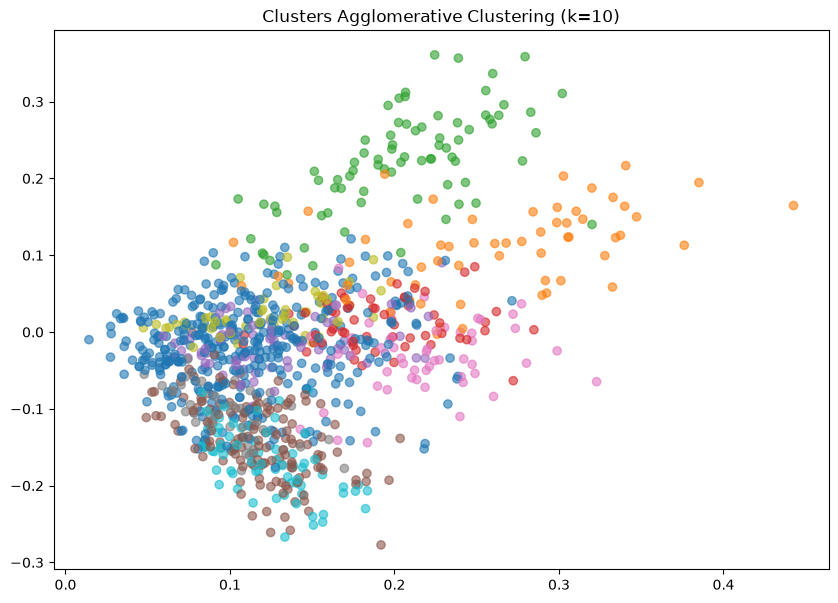

In [40]:
# Création du modèle de clustering agglomératif avec 10 clusters
# La méthode de Ward cherche à minimiser la dispersion au sein des clusters
modele_agglo = AgglomerativeClustering(n_clusters=10, linkage='ward')
labels_agglo = modele_agglo.fit_predict(X_reduced_final)

# Évaluation de la qualité des clusters avec le Silhouette Score
score = silhouette_score(X_reduced_final, labels_agglo)
print(f"Silhouette Score (Agglomerative) : {score:.4f}")

plt.figure(figsize=(10, 7))

# Affichage des témoignages avec une couleur par cluster
# Les deux premières composantes SVD sont utilisées pour les axes X et Y
plt.scatter(X_reduced_final[:, 0], X_reduced_final[:, 1], c=labels_agglo, cmap='tab10', alpha=0.6)

plt.title("Clusters Agglomerative Clustering (k=10)")

# Affichage du graphique
plt.show()

## Gausse Mélange Modèle

## Pourquoi avoir choisi le GMM pour ce projet CVRIE ?

Nous avons intégré le **GMM** à notre comparaison afin d’avoir une méthode différente de KMeans et du clustering agglomératif. Son fonctionnement présente plusieurs avantages intéressants pour notre dataset.

1. **Prendre en compte les situations où les symptômes se chevauchent :** En médecine, un même symptôme peut être associé à plusieurs situations différentes. Par exemple, la fatigue peut être présente dans plusieurs types de pathologies. Le GMM permet de prendre en compte cette incertitude en donnant une **probabilité d’appartenance à chaque cluster**, plutôt que de forcer le témoignage à appartenir à un seul groupe.

2. **Des clusters qui peuvent avoir des formes différentes :** KMeans fonctionne principalement autour de groupes relativement sphériques. Le GMM est plus flexible puisqu’il peut représenter des clusters de formes, de tailles et d’orientations différentes grâce à l’utilisation des matrices de covariance. Cela peut être intéressant pour nos données, qui ont été transformées dans un espace vectoriel avec **TF-IDF puis SVD**.

3. **Une approche basée sur les probabilités :** Le GMM ne fait pas que créer des groupes : il permet également d'estimer à quel point un témoignage correspond à chacun d'eux. On obtient ainsi une information supplémentaire sur le **niveau de confiance de l'affectation**. Cette information pourrait être intéressante dans une éventuelle utilisation future du modèle, notamment dans un outil d’aide à l’analyse des témoignages médicaux.

## Comment fonctionne le Gaussian Mixture Model (GMM) ?

Contrairement à KMeans, qui cherche à placer un centre au milieu de chaque groupe, le Gaussian Mixture Model (GMM) adopte une approche différente. Il considère que nos données peuvent être représentées comme un mélange de plusieurs **distributions gaussiennes**, c’est-à-dire des distributions en forme de cloche.
Pour trouver ces différentes distributions, le GMM utilise un algorithme itératif appelé **EM (Expectation-Maximization)**. Celui-ci fonctionne en deux étapes qui sont répétées jusqu’à ce que les résultats se stabilisent :

1. **Étape d’Espérance (E-step) :** Pour chaque témoignage, l’algorithme estime la probabilité qu’il appartienne à chacun des clusters. Contrairement à KMeans, un témoignage n’est donc pas forcément associé de manière définitive à un seul groupe. Par exemple, un témoignage peut avoir **70 % de chances d’appartenir au cluster A et 30 % au cluster B**. C’est ce qu’on appelle le **Soft Clustering**.

2. **Étape de Maximisation (M-step) :** À partir de ces probabilités, l’algorithme ajuste les paramètres de chaque distribution gaussienne. Il modifie notamment sa moyenne, sa variance et son poids afin que les distributions correspondent au mieux aux données.

Ces deux étapes sont répétées plusieurs fois jusqu’à obtenir une solution stable. Au final, chaque cluster est représenté par une distribution qui permet de décrire la zone dans laquelle se trouvent les données qui lui correspondent le mieux.




Silhouette Score (GMM) : 0.2350


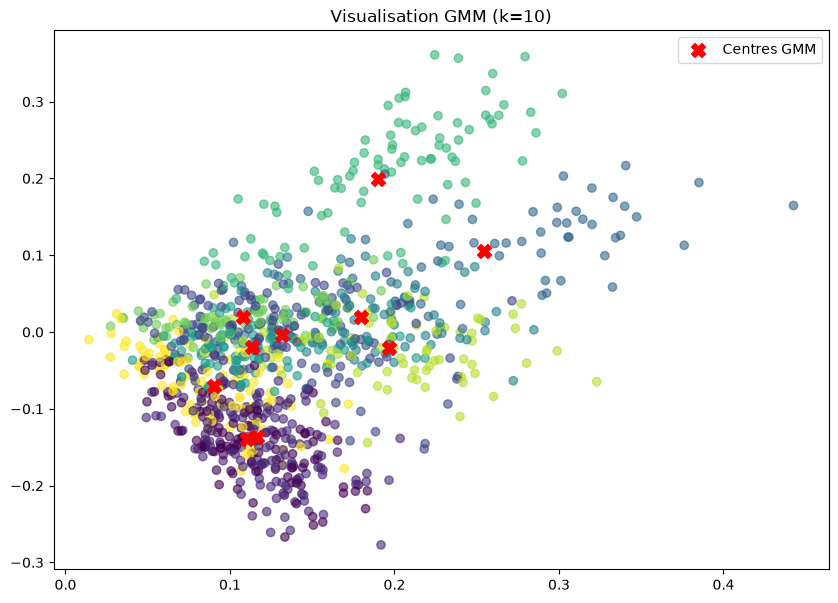

In [34]:
# Création du modèle GMM avec 10 composantes
gmm = GaussianMixture(
    n_components=10,
    random_state=42
).fit(X_reduced_final)

# Attribution de chaque témoignage à la composante la plus probable
labels_gmm = gmm.predict(X_reduced_final)

# Évaluation de la qualité des clusters avec le Silhouette Score
print(
    f"Silhouette Score (GMM) : "
    f"{silhouette_score(X_reduced_final, labels_gmm):.4f}"
)


# Création de la visualisation 2D
plt.figure(figsize=(10, 7))

# Affichage des témoignages avec une couleur par cluster
# Les deux premières composantes SVD sont utilisées pour les axes X et Y
plt.scatter(X_reduced_final[:, 0], X_reduced_final[:, 1], c=labels_gmm, cmap='viridis',alpha=0.6)

# Récupération des moyennes des composantes GMM
centres_gmm = gmm.means_[:, :2]

# Affichage des centres des composantes avec des X rouges
plt.scatter(centres_gmm[:, 0], centres_gmm[:, 1], c='red', marker='X', s=100, label='Centres GMM')

# Titre du graphique
plt.title("Visualisation GMM (k=10)")
plt.legend()
plt.show()

## DBSCAN


### Comment fonctionne DBSCAN ?

**DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) est une méthode de clustering qui se base principalement sur la **densité des données**.

Contrairement à KMeans, qui cherche à regrouper les données autour de centres, DBSCAN regarde plutôt quels points sont proches les uns des autres. Pour cela, il utilise deux paramètres principaux : **`eps`**, qui définit la distance maximale entre deux points pour qu'ils soient considérés comme voisins, et **`min_samples`**, qui correspond au nombre minimum de voisins nécessaires pour former une zone suffisamment dense.
À partir de ces paramètres, DBSCAN regroupe les points qui se trouvent dans des zones denses. L'un des avantages de cette méthode est qu'elle peut former des clusters avec des formes assez variées, sans forcément avoir des groupes parfaitement ronds ou réguliers.

Un autre point important est que DBSCAN peut identifier les points isolés. Lorsqu'un point ne se trouve pas dans une zone suffisamment dense, l'algorithme le considère comme du **bruit** et lui attribue l'étiquette **-1**. Il n'est donc pas obligé de placer chaque témoignage dans un cluster.

### Pourquoi l'avoir choisi pour ce projet CVRIE ?

Nous avons choisi d'intégrer DBSCAN à notre étude car son fonctionnement est différent des autres méthodes que nous avons utilisées.

1. **Une découverte automatique des groupes :** Contrairement à KMeans, nous n'avons pas besoin de définir directement le nombre de clusters à l'avance. DBSCAN identifie les groupes en fonction de la densité des données. Dans notre cas, cette méthode a permis d'obtenir **13 clusters**.

2. **La possibilité d'identifier les cas atypiques :** Certains témoignages peuvent être différents des autres, par exemple parce qu'ils sont plus rares, ambigus ou qu'ils présentent une combinaison de symptômes particulière. DBSCAN peut les identifier comme du bruit au lieu de les forcer à rejoindre un cluster qui ne leur correspond pas forcément. Cela nous permet donc de garder ces cas à part lors de l'analyse.

3. **Des formes de clusters plus flexibles :** DBSCAN ne suppose pas que les groupes doivent avoir une forme particulière. Il peut donc s'adapter à des regroupements plus irréguliers, ce qui peut être intéressant pour nos données après leur transformation avec **TF-IDF et TruncatedSVD**.

Au final, DBSCAN nous permet donc d'avoir une autre vision de notre dataset : au lieu de chercher uniquement à répartir tous les témoignages dans un nombre défini de groupes, il cherche à identifier les **zones où les données sont réellement concentrées**, tout en mettant de côté les observations qui semblent trop isolées.


DBSCAN : 13 clusters trouvés, 391 points de bruit


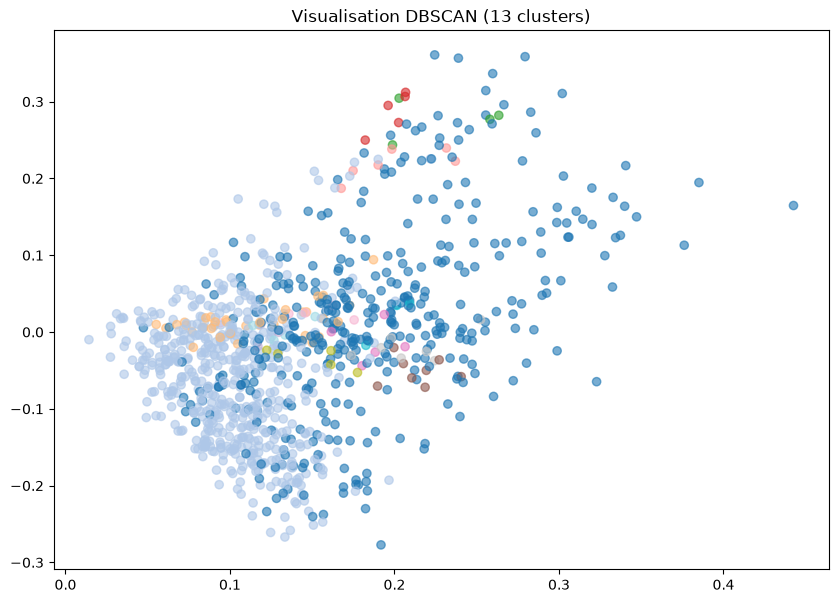

In [38]:
# Création du modèle DBSCAN
dbscan = DBSCAN(eps=0.1, min_samples=4)

# Attribution d'un cluster à chaque témoignage
# Les points considérés comme du bruit sont associés au label -1
labels_dbscan = dbscan.fit_predict(X_reduced_final)

# Calcul du nombre de clusters détectés, sans compter le bruit
n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)

# Comptage du nombre de points considérés comme du bruit
n_noise = list(labels_dbscan).count(-1)

# Affichage du nombre de clusters et de points de bruit
print(f"DBSCAN : {n_clusters} clusters trouvés, {n_noise} points de bruit")
plt.figure(figsize=(10, 7))

# Affichage des témoignages avec une couleur par cluster
# Les points de bruit sont identifiés par le label -1
# Les deux premières composantes SVD sont utilisées pour les axes X et Y
plt.scatter(X_reduced_final[:, 0], X_reduced_final[:, 1], c=labels_dbscan, cmap='tab20', alpha=0.6)

# Titre du graphique avec le nombre de clusters détectés
plt.title(f"Visualisation DBSCAN ({n_clusters} clusters)")

# Affichage du graphique
plt.show()

# Pour dbscan il n'y à pas de centroide natif, alors au lieu de les calculer je laisse ainsi

## comparaison 4 modèles


In [ ]:
# Regroupement des résultats des quatre modèles de clustering
modeles = {"KMeans": clusters, "Agglomerative": labels_agglo, "GMM": labels_gmm, "DBSCAN": labels_dbscan}
print("Comparaison des modèles de clustering :\n")


# Parcours des différents modèles pour calculer leurs performances
for nom, labels in modeles.items():

    # dbscan utilise le label -1 pour identifier les points considérés comme du bruit
    if nom == "DBSCAN":

        # Exclusion des points de bruit pour le calcul du Silhouette Score
        mask = labels != -1
        X_calc = X_reduced_final[mask]
        labels_calc = labels[mask]

        # Calcul du nombre de clusters et de points de bruit
        nb_clusters = len(set(labels)) - 1
        nb_bruit = sum(labels == -1)

    else:

        # Pour les autres modèles, tous les points sont pris en compte
        X_calc = X_reduced_final
        labels_calc = labels

        # Calcul du nombre de clusters
        nb_clusters = len(set(labels))

        # Aucun point de bruit n'est identifié
        nb_bruit = 0


    # Le Silhouette Score nécessite au moins deux clusters
    if nb_clusters > 1:
        score = silhouette_score(X_calc, labels_calc)
    else:
        score = 0.0

    # Affichage des résultats pour chaque modèle
    print(f"{nom:<15} | Score : {score:.4f} " f"| Clusters : {nb_clusters} " f"| Bruit : {nb_bruit}")

Comparaison des modèles de clustering :

KMeans          | Score : 0.3041 | Clusters : 10 | Bruit : 0
Agglomerative   | Score : 0.2821 | Clusters : 10 | Bruit : 0
GMM             | Score : 0.2350 | Clusters : 10 | Bruit : 0
DBSCAN          | Score : 0.0245 | Clusters : 13 | Bruit : 391
